In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
from sklearn.model_selection import train_test_split

data = loadmat("train_32x32.mat")
print(data.keys())

X = data["X"]
y = data["y"]
print(X.shape, y.shape)
X = X.T
X = X.reshape(X.shape[0], -1).astype("float32") / 255.0
y = y.ravel()% 10

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.10, random_state=42
# )


X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42
)

# 25% of the remaining 80% = 20% of the full dataset
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.22, random_state=42
)
print(X_train.shape, y_train.shape, X_valid.shape, y_valid.shape, X_test.shape, y_test.shape)


I0000 00:00:1795541488.317727    8224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795541490.026422    8224 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


KeyboardInterrupt: 

In [ ]:
print("X_train shape:", X_train.shape)
print("One sample shape:", X_train[0].shape)
print("Features per sample:", X_train[0].size)

X_train shape: (51426, 3, 32, 32)
One sample shape: (3, 32, 32)
Features per sample: 3072


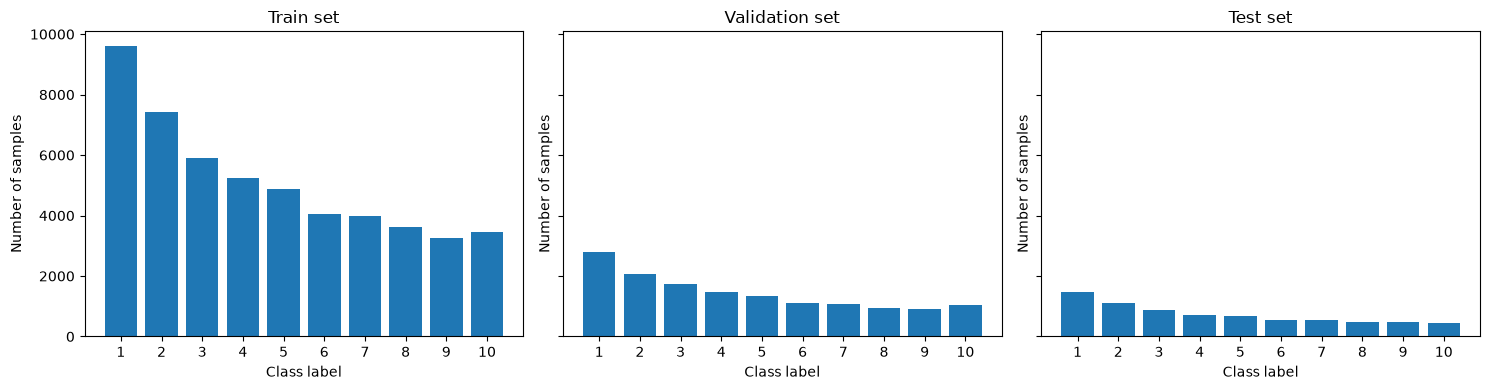

In [ ]:
splits = {
    "Train": y_train,
    "Validation": y_valid,
    "Test": y_test,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (name, labels) in zip(axes, splits.items()):
    classes, counts = np.unique(labels, return_counts=True)
    ax.bar(classes.astype(str), counts)
    ax.set_title(f"{name} set")
    ax.set_xlabel("Class label")
    ax.set_ylabel("Number of samples")

plt.tight_layout()
plt.show()

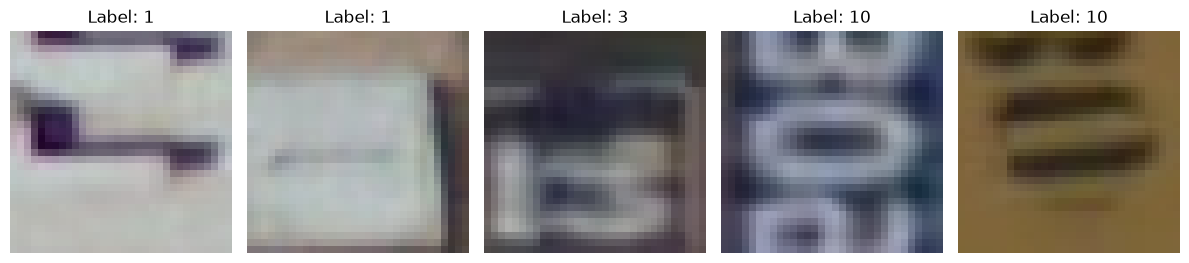

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, ax in enumerate(axes):
    image = X_train[i].transpose(1, 2, 0)  # (3, 32, 32) -> (32, 32, 3)
    ax.imshow(image)
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def plot_loss(history):
    plt.plot(history.history['loss'], label='loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.xlabel('Epoch')
    plt.ylabel('Binary crossentropy')
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_accuracy(history):
    plt.plot(history.history['accuracy'], label='accuracy')
    plt.plot(history.history['val_accuracy'], label='val_accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

nn_model = keras.Sequential([
    layers.Input(shape=(3, 32, 32)),  # one image in your current X layout
    layers.Permute((2, 3, 1)),        # (channels, height, width) -> (height, width, channels)
    layers.Flatten(),                 # 32 × 32 × 3 = 3,072 inputs

    layers.Dense(128, activation="relu"),  # hidden layer 1
    layers.Dense(64, activation="relu"),   # hidden layer 2

    layers.Dense(10, activation="softmax") # output: 10 digit classes
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history=nn_model.fit(X_train, y_train, epochs=100, 
          batch_size=2000, 
          validation_split=0.2, verbose=0)

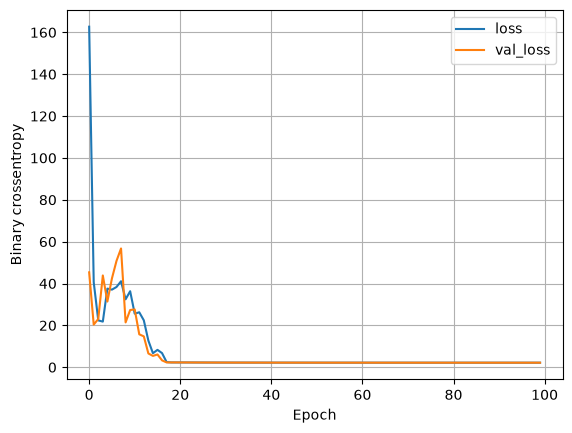

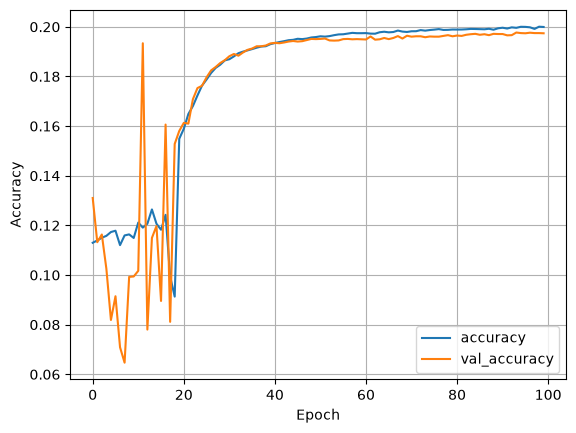

In [ ]:
plot_loss(history)
plot_accuracy(history)

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    batch_size=150,
    max_iter=15,
    verbose=1
)

param_grid = {
    'hidden_layer_sizes': [(128,64),(300, 300), (500, 500),(600,600)],
    'batch_size': [50,100,150],
    'max_iter': [10, 15, 17]
}

search = GridSearchCV(mlp, param_grid, cv=3, scoring="accuracy", n_jobs=5, verbose=1)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Validation accuracy:", search.best_estimator_.score(X_valid, y_valid))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Iteration 1, loss = 2.26049157
Iteration 1, loss = 2.25814281
Iteration 1, loss = 2.23594704
Iteration 1, loss = 2.26684005
Iteration 1, loss = 2.24624965
Iteration 2, loss = 2.08498755
Iteration 2, loss = 2.04971306
Iteration 2, loss = 1.87284654
Iteration 2, loss = 2.10771872
Iteration 2, loss = 2.03549337
Iteration 3, loss = 1.63100083
Iteration 3, loss = 1.68578135
Iteration 3, loss = 1.56559349
Iteration 3, loss = 1.81437442
Iteration 3, loss = 1.87438664
Iteration 4, loss = 1.39213995
Iteration 4, loss = 1.44418639
Iteration 4, loss = 1.53135778
Iteration 4, loss = 1.57292157
Iteration 5, loss = 1.30244621
Iteration 4, loss = 1.78052129
Iteration 5, loss = 1.33815061
Iteration 5, loss = 1.48287374
Iteration 5, loss = 1.42639841
Iteration 6, loss = 1.23065451
Iteration 5, loss = 1.74713040
Iteration 6, loss = 1.27590675
Iteration 6, loss = 1.44575806
Iteration 6, loss = 1.30986545
Iteration 7, loss = 1.17483321
Iteratio

/home/abhi/miniconda3/envs/ml-assignment/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


Iteration 10, loss = 1.27687882


/home/abhi/miniconda3/envs/ml-assignment/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


Iteration 11, loss = 1.08026782
Iteration 9, loss = 1.55890783


/home/abhi/miniconda3/envs/ml-assignment/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


... (209 outputs left out)

/home/abhi/miniconda3/envs/ml-assignment/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (17) reached and the optimization hasn't converged yet.
  warnings.warn(


Iteration 1, loss = 2.24192492
Iteration 2, loss = 1.80964975
Iteration 3, loss = 1.42001793
Iteration 4, loss = 1.25027946
Iteration 5, loss = 1.18230091
Iteration 6, loss = 1.12925054
Iteration 7, loss = 1.10202516
Iteration 8, loss = 1.07035587
Iteration 9, loss = 1.05328236
Iteration 10, loss = 1.02981470
Iteration 11, loss = 1.01399940
Iteration 12, loss = 0.99999191
Iteration 13, loss = 0.98655543
Iteration 14, loss = 0.98046210
Iteration 15, loss = 0.97253710
Iteration 16, loss = 0.96846593
Iteration 17, loss = 0.96279147
Best parameters: {'batch_size': 150, 'hidden_layer_sizes': (300, 300), 'max_iter': 17}


/home/abhi/miniconda3/envs/ml-assignment/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (17) reached and the optimization hasn't converged yet.
  warnings.warn(


Validation accuracy: 0.709617373319545


In [ ]:
from sklearn.metrics import log_loss

activations = {
    "sigmoid": "logistic",
    "ReLU": "relu",
    "tanh": "tanh",
    "linear": "identity",
}

best_params=search.best_params_.copy()
epochs=15
classes=np.unique(y_train)
losses={}

for name, activation in activations.items():
    model = MLPClassifier(
        **best_params,
        activation=activation,
        max_iter=1,
        random_state=42
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        if epoch == 0:
            model.partial_fit(X_train, y_train, classes=classes)
        else:
            model.partial_fit(X_train, y_train)

        train_losses.append(model.loss_)
        val_probabilities = model.predict_proba(X_valid)
        val_losses.append(log_loss(y_valid, val_probabilities, labels=classes))

    losses[name] = (train_losses, val_losses)

In [ ]:
for name, (train_losses, val_losses) in losses.items():
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, epochs + 1), train_losses, label="Training loss")
    plt.plot(range(1, epochs + 1), val_losses, label="Validation loss")

    plt.title(f"{name} activation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()